# Эхо-сигнал: два класса без путаницы

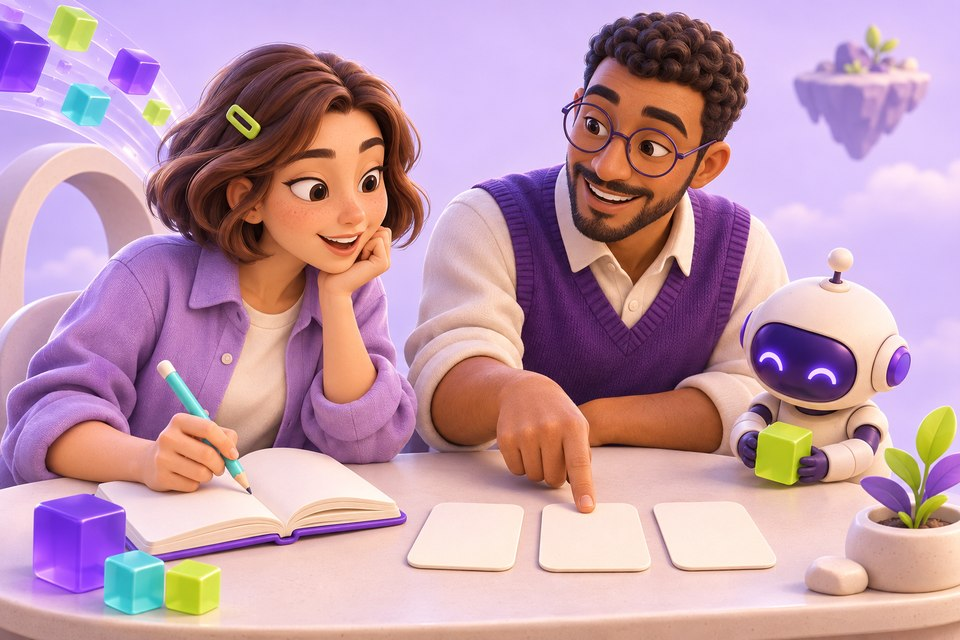

**Создадим измерения датчиков и отдельную проверку.**

**Твой результат:** Обучить бинарную модель с нормировкой только по train.

**Что разбираем:** Учебный аналог классификации Sonar; не реальная система обнаружения мин и не архивная нейросеть.

**Данные:** Синтетические 60-мерные эхо-сигналы двух условных классов.

**Перед началом:**

- Python 3 и указанные библиотеки
- Запускай шаги сверху вниз

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. [Подготовь измерения и три набора](#step-1)
2. [Обучи компактную модель](#step-2)
3. [Разбери итоговую таблицу ответов](#step-3)

[Твой эксперимент](#your-experiment)

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **numpy, matplotlib, scikit-learn**.

In [1]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams.update({
    'figure.figsize': (7, 3.5), 'figure.dpi': 100,
    'figure.facecolor': '#fffdf8', 'axes.facecolor': '#fffdf8',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelcolor': '#302c3f',
    'text.color': '#302c3f', 'savefig.bbox': 'tight',
})
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
rng = np.random.default_rng(11)


<a id="step-1"></a>

## 1. Подготовь измерения и три набора

Каждому сигналу соответствует один класс 0 или 1. Это классификация, а не прогноз непрерывного числа.

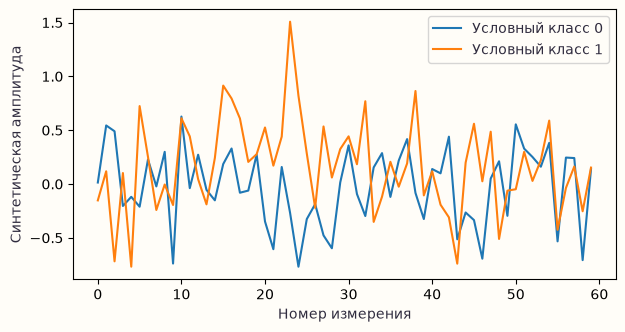

In [2]:
y = np.repeat([0, 1], 80)
X = rng.normal(0, 0.4, (160, 60))
X[:, 15:25] += y[:, None] * 0.8
ids = np.arange(len(y))
train_val, test = train_test_split(ids, test_size=0.2, stratify=y, random_state=11)
train, val = train_test_split(train_val, test_size=0.25, stratify=y[train_val], random_state=11)
x_train, y_train = X[train], y[train]
x_val, y_val = X[val], y[val]
x_test, y_test = X[test], y[test]
assert set(train).isdisjoint(val) and set(train_val).isdisjoint(test)
assert x_val.shape == (len(y_val), 60)
plt.plot(X[0], label='Условный класс 0')
plt.plot(X[-1], label='Условный класс 1')
plt.xlabel('Номер измерения')
plt.ylabel('Синтетическая амплитуда')
plt.legend()
plt.show()


**Что проверить:** Два сигнала и явно созданная validation-группа.

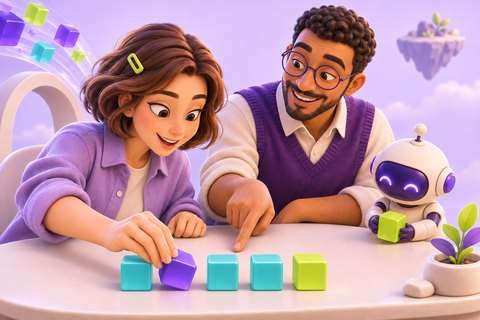

> **Мира:** Откуда раньше появлялась x_val?

> **Данил:** В старом коде она использовалась без создания. Теперь все три набора определены явно.

> **Пикс:** Перед обучением проверь пары x_val и y_val.

<a id="step-2"></a>

## 2. Обучи компактную модель

Pipeline сначала учит нормировку на train, затем классификатор. К val применяются уже готовые параметры.

In [3]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=200, random_state=11))
model.fit(x_train, y_train)
scaler = model.named_steps['standardscaler']
assert np.allclose(scaler.mean_, x_train.mean(axis=0))
assert scaler.n_samples_seen_ == len(x_train)
validation_accuracy = model.score(x_val, y_val)
print(f'Проверка на синтетических сигналах: {validation_accuracy:.3f}')
print('Строк использовано для нормировки:', scaler.n_samples_seen_)


Проверка на синтетических сигналах: 1.000
Строк использовано для нормировки: 96.0


**Что проверить:** Измеренная оценка val; масштаб получен только из train.

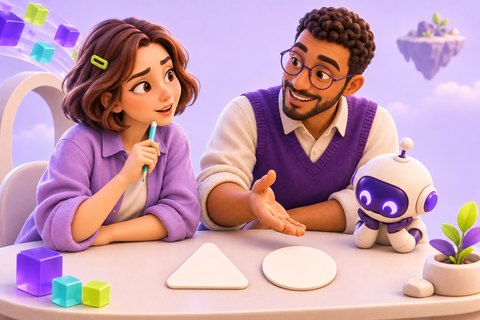

> **Мира:** Зачем не нормировать всю таблицу сразу?

> **Данил:** Тогда сведения о проверочных сигналах попадут в обучение.

> **Пикс:** Средние scaler совпадают со средними x_train.

<a id="step-3"></a>

## 3. Разбери итоговую таблицу ответов

Порог 0.5 задан заранее. Матрица показывает правильные и ошибочные ответы отдельно для каждого класса.

In [4]:
probability = model.predict_proba(x_test)[:, 1]
predicted = (probability >= 0.5).astype(int)
confusion = np.zeros((2, 2), dtype=int)
np.add.at(confusion, (y_test, predicted), 1)
assert confusion.sum() == len(y_test)
assert np.all((probability >= 0) & (probability <= 1))
print('Строки: истинный класс; колонки: ответ')
print(confusion)
print(f'Итоговая доля совпадений: {np.mean(predicted == y_test):.3f}')


Строки: истинный класс; колонки: ответ
[[15  1]
 [ 0 16]]
Итоговая доля совпадений: 0.969


**Что проверить:** Матрица содержит ровно столько ответов, сколько примеров в test.

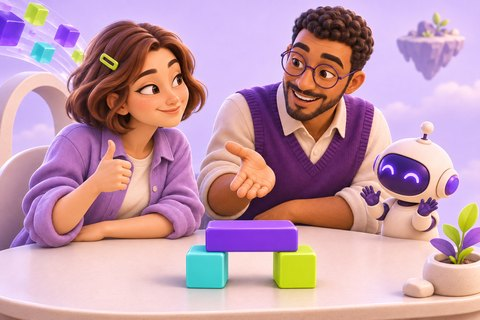

> **Мира:** Число 0.9 — это гарантия правильности?

> **Данил:** Нет. Это выход модели на искусственных данных; реальное применение требует отдельной проверки.

> **Пикс:** Сумма матрицы должна совпадать с размером test.

<a id="your-experiment"></a>

## Попробуй сам

Ослабь различие классов с 0.8 до 0.3.

**Где изменить:** Добавка к X[:,15:25] в первом шаге.

**Как проверить:** Сравни матрицу ошибок; независимость наборов сохраняется.

## Что теперь умеешь

- Два класса — задача классификации.
- Обработка данных тоже обучается только на train.

## Границы этого примера

- Нет реальных Sonar-данных и оценок пригодности оборудования.
- Исторические 91% здесь не заявляются.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/Classification/Pro_%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%A6%D0%B5%D0%BB%D1%8C_%3D_90_%D1%82%D0%BE%D1%87%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D0%B1%D0%B0%D0%B7%D0%B0_%D0%9C%D0%98%D0%9D%D0%AB_%D0%BD%D0%B0_%D1%82%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%BE%D0%B9_%D0%B2%D1%8B%D0%B1%D0%BE%D0%BA%D0%B5.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/Pro_%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%A6%D0%B5%D0%BB%D1%8C_%3D_90_%D1%82%D0%BE%D1%87%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D0%B1%D0%B0%D0%B7%D0%B0_%D0%9C%D0%98%D0%9D%D0%AB_%D0%BD%D0%B0_%D1%82%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%BE%D0%B9_%D0%B2%D1%8B%D0%B1%D0%BE%D0%BA%D0%B5.ipynb>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 13 (от 0).** Обучение использует несуществующие x_val и y_val. → Пары train/val/test создаются явно.

Проверка: x_val.shape==(len(y_val),60).

Фрагмент исходника: <code>validation_data=(x_val,y_val)</code>

---

**Понятнее для новичка · исходная ячейка 1 (от 0).** Бинарная задача ошибочно названа регрессией. → Урок называет задачу классификацией.

Проверка: Метки и ответы принадлежат {0,1}.

Фрагмент исходника: <code>Заголовок: Задача регрессии; выход sigmoid и binary_crossentropy.</code>

</details>